# Part 5 · Evaluating five-frame deepfake explanations
**Kaggle implementation study • FaceForensics++ subset of ExDDV**

Run all cells. The first half works offline on CPU and recreates figures from the four supplied executed notebooks. The second half scores the original 271 test predictions side by side. Attach the **extracted** Part 3 and Part 4 output folders, each containing its own test_predictions.csv. For new qualitative panels attach Part 1 metadata.csv with its sibling crops/ and Part 2 click_preds.csv. Raw videos and BLIP-2 checkpoints are unnecessary. Enable Internet for metric models; GPU 0 accelerates scoring. All paths can be set below.

The notebook exports labelled PNG figures, PDF copies of charts, CSV tables, a caption guide and a ZIP under /kaggle/working. If neither prediction file is mounted, the notebook produces only the recorded-results pack. A partial or conflicting pair raises an error. The saved run summaries do not contain all 271 paired captions.

In [1]:
import os, sys, json, hashlib, shutil, subprocess, textwrap, tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, FileLink
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
ROOT = Path("/kaggle/input")
FULL_CSV = MASK_CSV = META_CSV = CLICK_CSV = None   # optional absolute paths
WORK = Path("/kaggle/working")
WORK.mkdir(exist_ok=True, parents=True)
OUT = Path(tempfile.mkdtemp(prefix="part5_",dir=WORK))
FIG = OUT/"figures"
FIG.mkdir()
captions = {}
blue, orange, grey = "#246491", "#b95328", "#5b6870"
plt.rcParams.update({"figure.dpi":110,"axes.spines.top":False,"axes.spines.right":False,
                     "font.size":11,"axes.titlelocation":"left","axes.titleweight":"bold"})
def save(fig, name, caption):
    fig.savefig(FIG/(name+".png"),dpi=300,bbox_inches="tight",facecolor="white")
    fig.savefig(FIG/(name+".pdf"),bbox_inches="tight",facecolor="white")
    captions[name]=caption
    display(fig)
    plt.close(fig)
def table(df,name):
    df.to_csv(OUT/(name+".csv"),index=False)
    display(df.round(4))

## 1. Recorded training and held-out results
These values come from the saved outputs of Parts 2–4. Baseline epochs were printed to three decimals. Select the checkpoint by validation loss within each run. Loss aggregation and optimisation differ between runs; the curves are best read as within-run trends.

,epoch,train,validation,system
0,1,2.0650,1.7290,Full crop
1,2,1.5350,1.6270,Full crop
2,3,1.3680,1.5640,Full crop
3,4,1.2120,1.5890,Full crop
4,5,1.0260,1.6550,Full crop
5,6,0.8000,1.8810,Full crop
6,7,0.5580,2.3330,Full crop
7,8,0.3650,2.7530,Full crop
8,9,0.2300,3.4150,Full crop
9,10,0.1720,3.6620,Full crop


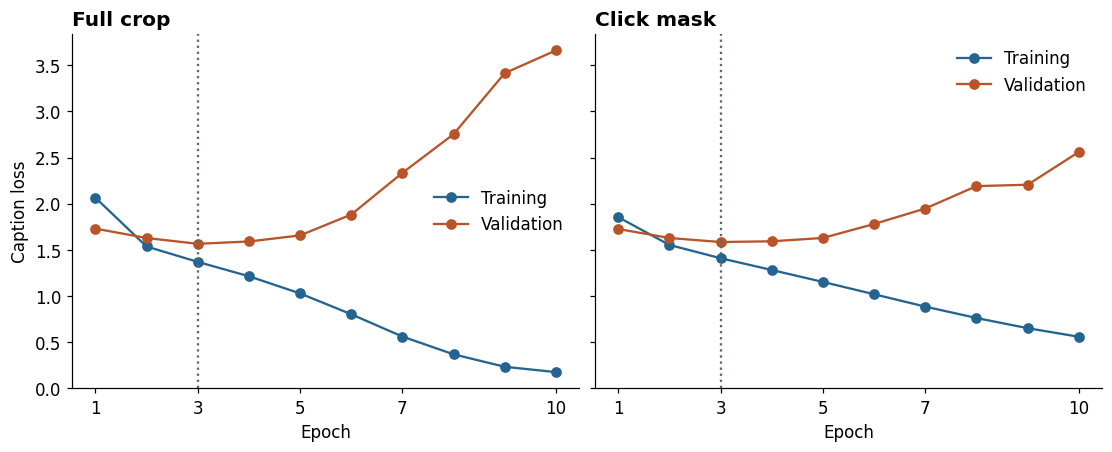

In [2]:
history = pd.concat([pd.DataFrame(values,columns=["epoch","train","validation"]).assign(system=label)
                     for label,values in [("Full crop",[[1, 2.065, 1.729], [2, 1.535, 1.627], [3, 1.368, 1.564], [4, 1.212, 1.589], [5, 1.026, 1.655], [6, 0.8, 1.881], [7, 0.558, 2.333], [8, 0.365, 2.753], [9, 0.23, 3.415], [10, 0.172, 3.662]]),("Click mask",[[1, 1.8532904140431377, 1.7245080546705824], [2, 1.551407269074244, 1.6270515006946973], [3, 1.407579433385702, 1.5833109510997017], [4, 1.279626267295648, 1.591119956180599], [5, 1.1502877112472272, 1.6276137980565986], [6, 1.0168235477397916, 1.778900029797319], [7, 0.8824853930589056, 1.9469338513589416], [8, 0.7588915040900073, 2.1896781412862314], [9, 0.6486512364545799, 2.204838888258574], [10, 0.5555475429209005, 2.560069300172207]])]],ignore_index=True)
table(history,"recorded_training")
fig, axes = plt.subplots(1,2,figsize=(10,4),sharey=True,layout="constrained")
for ax,(name,h) in zip(axes,history.groupby("system",sort=False)):
    ax.plot(h.epoch,h.train,color=blue,marker="o",label="Training")
    ax.plot(h.epoch,h.validation,color=orange,marker="o",label="Validation")
    best=h.loc[h.validation.idxmin()]
    ax.axvline(best.epoch,ls=":",color=grey)
    ax.set(title=name,xlabel="Epoch",xticks=[1,3,5,7,10])
    ax.legend(frameon=False)
axes[0].set_ylabel("Caption loss")
save(fig,"01_training","Both validation minima occur at epoch 3. Training loss continues to fall as validation loss rises.")

,system,SBERT,ROUGE-L
0,Constant,0.437,0.178
1,Shuffled full crop,0.515,0.255
2,Correct full crop,0.564,0.282


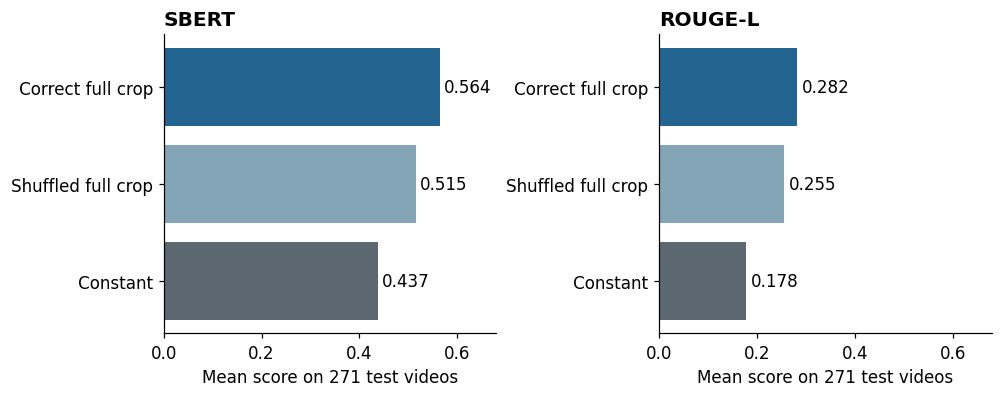

,system,weighted_error_px,hit_percent
0,Centre,45.782,46.0
1,Train mean,45.148,53.2
2,DeiT-Small,41.441,57.7


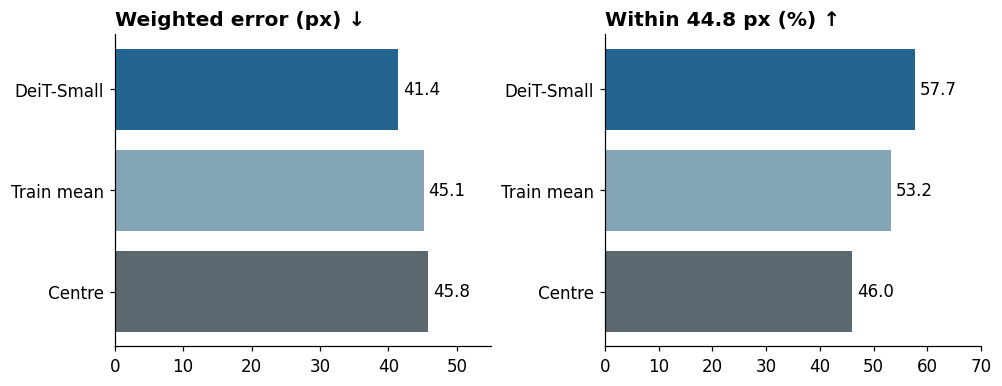

In [3]:
systems=["Constant","Shuffled full crop","Correct full crop"]
recorded=pd.DataFrame({"system":systems,"SBERT":[.437,.515,.564],"ROUGE-L":[.178,.255,.282]})
table(recorded,"recorded_caption_controls")
fig,axes=plt.subplots(1,2,figsize=(9,3.5),layout="constrained")
for ax,metric in zip(axes,["SBERT","ROUGE-L"]):
    bars=ax.barh(systems,recorded[metric],color=[grey,"#83a5b6",blue])
    ax.bar_label(bars,fmt="%.3f",padding=3)
    ax.set(xlim=(0,.68),title=metric,xlabel="Mean score on 271 test videos")
save(fig,"02_caption_controls","Part 3, original split. Correct pairing raises SBERT by 0.049 over one shuffled assignment; semantic similarity is not classification accuracy.")
click=pd.DataFrame({"system":["Centre","Train mean","DeiT-Small"],"weighted_error_px":[45.782,45.148,41.441],"hit_percent":[46,53.2,57.7]})
table(click,"recorded_click_localisation")
fig,axes=plt.subplots(1,2,figsize=(9,3.4),layout="constrained")
for ax,col,title,lim in zip(axes,["weighted_error_px","hit_percent"],["Weighted error (px) ↓","Within 44.8 px (%) ↑"],[55,70]):
    bar=ax.barh(click.system,click[col],color=[grey,"#83a5b6",blue])
    ax.bar_label(bar,fmt="%.1f",padding=3)
    ax.set(title=title,xlim=(0,lim))
save(fig,"03_click_localisation","Part 2, 1,310 eligible frames from 262 test videos. The learned point improves on the training-mean location by 4.5 percentage points in hit rate.")

## 2. Actual run images
The panels below are embedded copies of the submitted notebooks’ rendered outputs. The Part 2 panel illustrates the localiser. The three Part 4 previews show training crops before and after masking; they illustrate preprocessing and must not be presented as held-out caption examples.

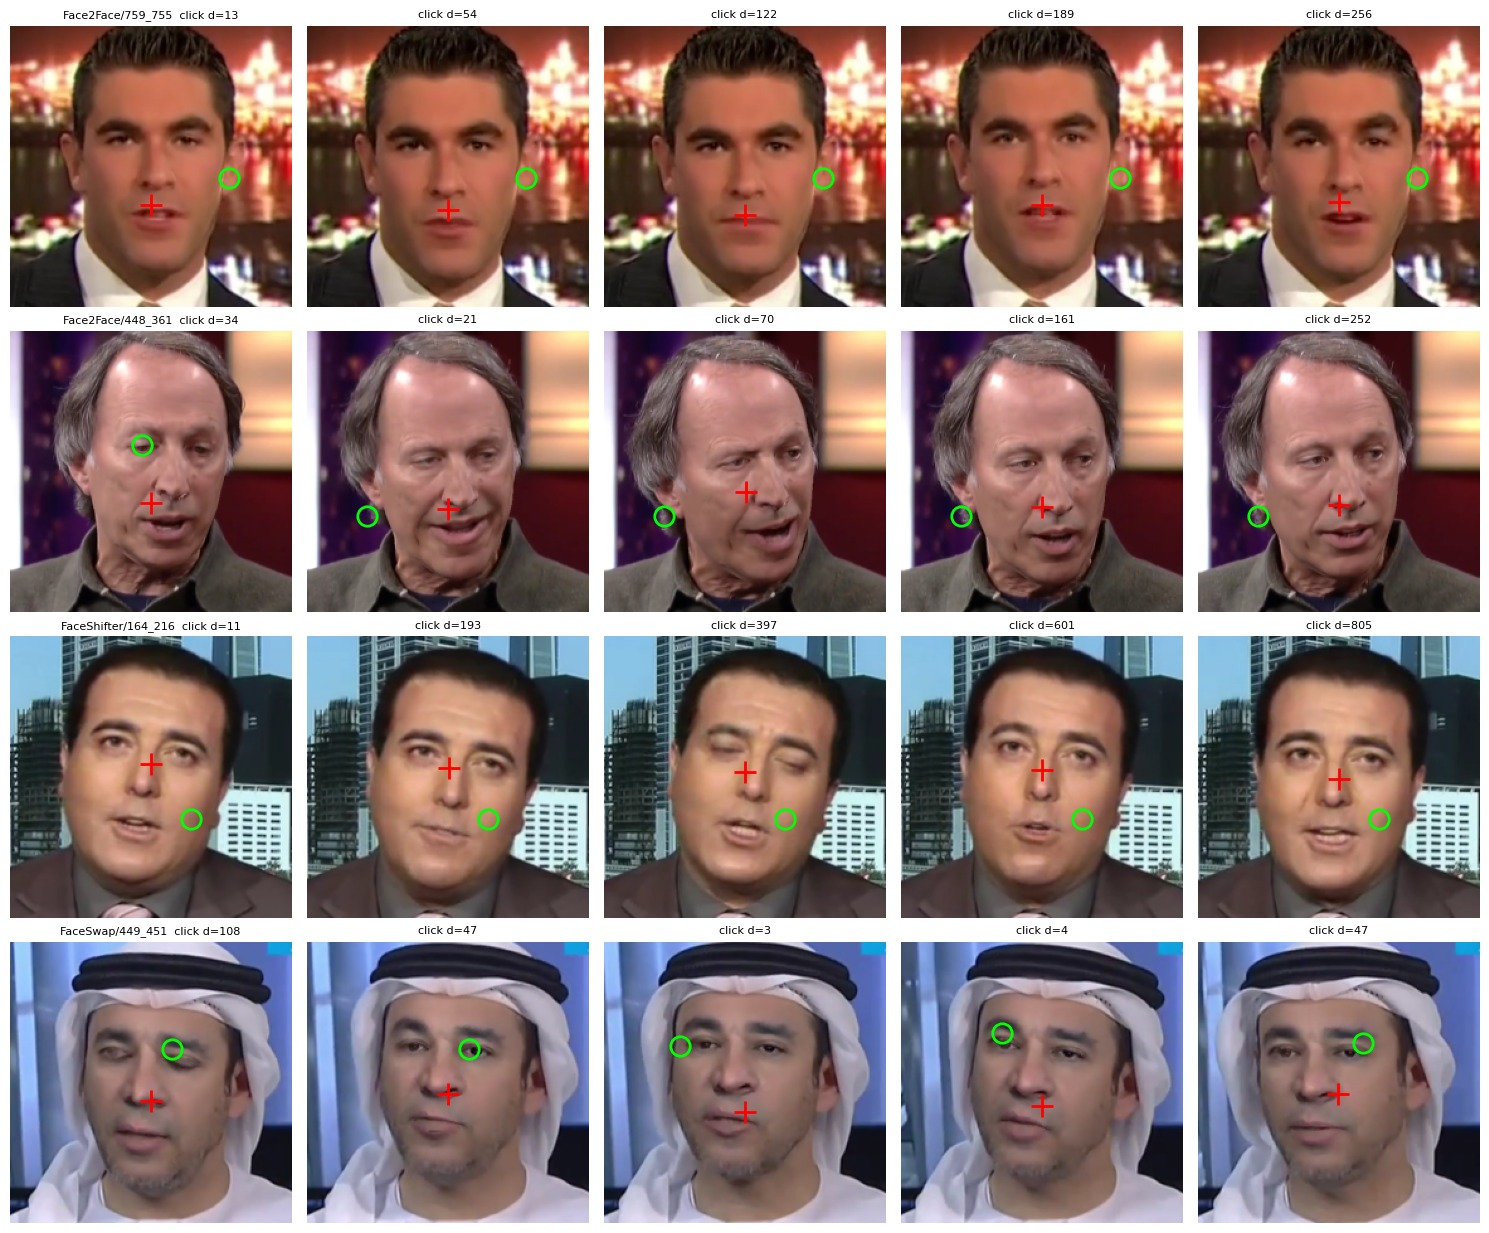

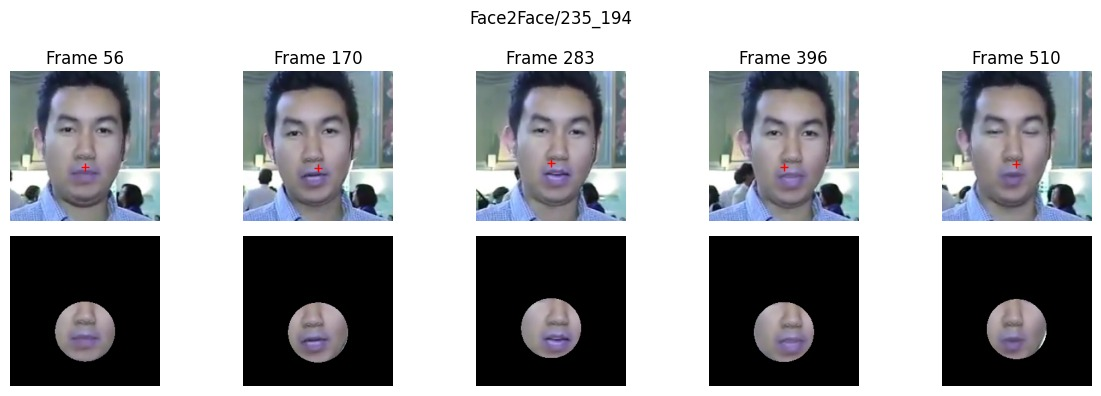

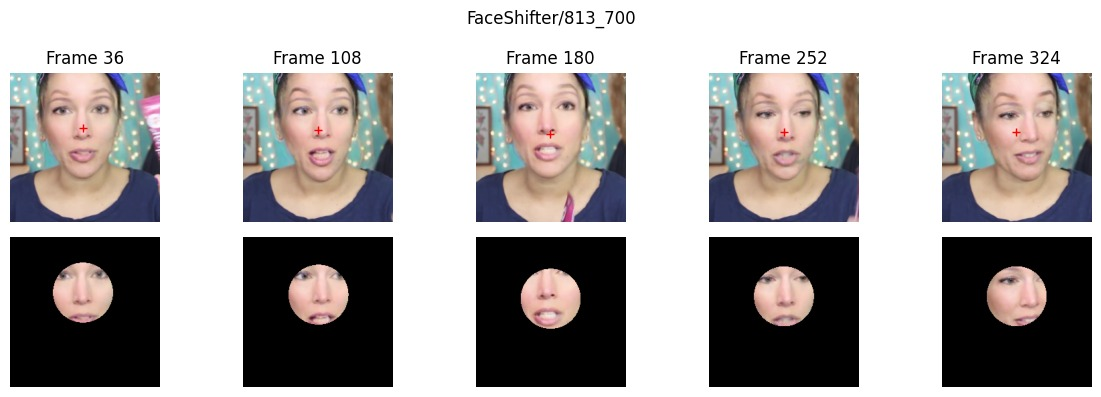

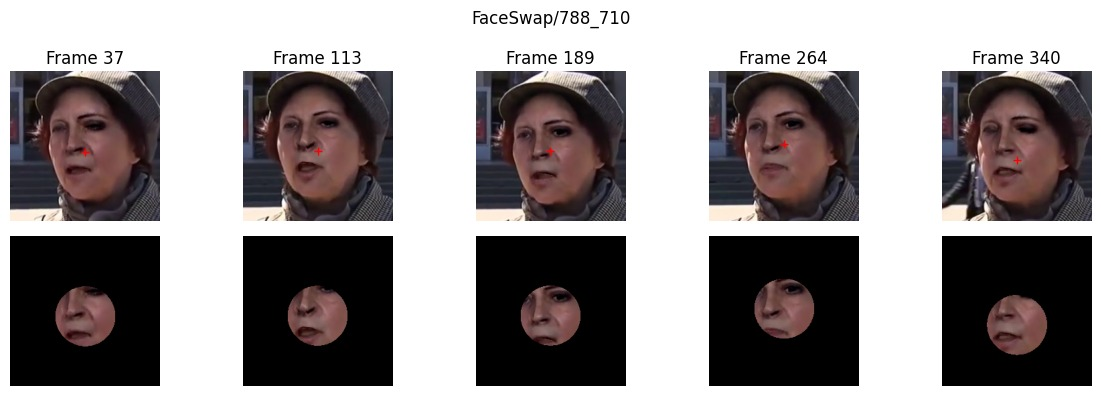

In [4]:
import base64
# Embedded original run panels (JPEG copies).
assets={'04_click_examples': '...', '05_mask_preview_1': '...', '05_mask_preview_2': '...', '05_mask_preview_3': '...'}
for name,data in assets.items():
    path=FIG/(name+".jpg")
    path.write_bytes(base64.b64decode(data))
    captions[name]=("Part 2 click prediction examples; symbols follow the original notebook." if "click" in name
                    else "Part 4 training preview. Top: predicted location on face crop. Bottom: actual masked input.")
    display(Image.open(path))

## 3. Match exports and audit the cohort
Keys contain both manipulation and filename stem. We check uniqueness, reference agreement, original split sizes and the shuffled assignment. Empty generated captions count as failures; they stay in the denominator.

In [5]:
def find_export(name, columns, override=None):
    paths=[Path(override)] if override else sorted(ROOT.rglob(name))
    matches=[p for p in paths if p.is_file() and set(columns)<=set(pd.read_csv(p,nrows=0).columns)]
    if (override and len(matches)!=1) or len(matches)>1:
        raise ValueError(f"Set the path for {name} with columns {columns}. Matches: {matches}")
    return matches[0] if matches else None
a=find_export("test_predictions.csv",["pred","pred_shuffled","shuffled_from"],FULL_CSV)
b=find_export("test_predictions.csv",["prediction","source_in_original_train"],MASK_CSV)
if bool(a)!=bool(b):
    raise ValueError("Attach both full-run output folders or set FULL_CSV and MASK_CSV.")
paired=a is not None
def flag(col):
    s=col.astype(str).str.lower().map({"true":True,"false":False,"1":True,"0":False})
    if s.isna().any(): raise ValueError("Invalid source flag")
    return s.astype(bool)
def join_exports(a,b):
    left=pd.read_csv(a,keep_default_na=False)
    right=pd.read_csv(b,keep_default_na=False)
    d=left.merge(right,on="key",how="outer",validate="one_to_one",indicator=True,suffixes=("","_mask"))
    assert d._merge.eq("both").all() and len(d)==271,"Incomplete or mismatched test keys"
    assert d.reference.str.strip().eq(d.reference_mask.str.strip()).all() and d.reference.str.strip().ne("").all()
    assert d.manipulation.eq(d.manipulation_mask).all() and d.split.eq("test").all()
    assert d.key.str.split("/").str[0].eq(d.manipulation).all()
    assert d.manipulation.value_counts().to_dict()=={"FaceSwap":91,"Face2Face":90,"FaceShifter":90}
    assert set(d.shuffled_from)==set(d.key) and d.shuffled_from.ne(d.key).all()
    d["seen"]=flag(d.id_in_train)
    assert d.seen.eq(flag(d.source_in_original_train)).all() and d.seen.sum()==256
    return d.rename(columns={"pred":"Full crop","prediction":"Click mask","pred_shuffled":"Shuffled full crop"}).assign(Constant="The eyes are blurry.")
if paired:
    d=join_exports(a,b)
    print("Validated",len(d),"paired videos")
else:
    print("Recorded-results mode. Attach Part 3 and 4 CSV exports to compute the complete comparison.")

Validated 271 paired videos


## 4. Score each caption with a common metric configuration
SBERT uses MiniLM-L6-v2 and cosine similarity. ROUGE-L uses stemmed F1 as in Part 3. BERTScore uses English RoBERTa-large layer 17, raw F1, no IDF or baseline rescaling. Its scale is configuration-specific. Empty outputs receive zero for all three metrics. The classifiers, caption generators and click regressor are never retrained. A metric download requires Internet on first use.

In [6]:
if paired:
    subprocess.run([sys.executable,"-m","pip","install","-q","transformers==4.57.6","sentence-transformers>=5.1,<6","bert-score==0.3.13","rouge-score==0.1.2"],check=True)
    os.environ.update(USE_TF="0",USE_FLAX="0",TOKENIZERS_PARALLELISM="false")
    import torch, gc
    from sentence_transformers import SentenceTransformer
    from rouge_score import rouge_scorer
    from bert_score import BERTScorer
    from importlib.metadata import version
    device="cuda:0" if torch.cuda.is_available() else "cpu"
    labels=["Constant","Shuffled full crop","Full crop","Click mask"]
    rows=d.melt(id_vars=["key","manipulation","seen","reference"],value_vars=labels,var_name="system",value_name="caption")
    sentences=pd.unique(pd.concat([rows.reference,rows.caption],ignore_index=True)).tolist()
    encoder=SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2",device=device)
    emb=dict(zip(sentences,encoder.encode(sentences,normalize_embeddings=True,show_progress_bar=True)))
    del encoder
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    rouge=rouge_scorer.RougeScorer(["rougeL"],use_stemmer=True)
    rows["SBERT"]=[float(np.dot(emb[r],emb[p])) if p.strip() else 0 for r,p in zip(rows.reference,rows.caption)]
    rows["ROUGE-L"]=[rouge.score(r,p)["rougeL"].fmeasure if p.strip() else 0 for r,p in zip(rows.reference,rows.caption)]
    scorer=BERTScorer(model_type="roberta-large",num_layers=17,lang="en",idf=False,rescale_with_baseline=False,device=device,batch_size=8)
    valid=rows.caption.str.strip().ne("")
    rows["BERTScore"]=0.
    _,_,f1=scorer.score(rows.loc[valid,"caption"].tolist(),rows.loc[valid,"reference"].tolist())
    rows.loc[valid,"BERTScore"]=f1.cpu().numpy()
    metrics=["SBERT","ROUGE-L","BERTScore"]
    assert np.isfinite(rows[metrics].to_numpy()).all()
    rows.to_csv(OUT/"per_video_scores.csv",index=False)
    (OUT/"metric_config.json").write_text(json.dumps({"bert_score_hash":scorer.hash,"sbert":"all-MiniLM-L6-v2",
        "rouge":"rougeL F1, stemmed","inputs":{str(p):hashlib.sha256(p.read_bytes()).hexdigest() for p in [a,b]},
        "versions":{k:version(k) for k in ["torch","transformers","sentence-transformers","bert-score","rouge-score"]}},indent=2))

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.42.0 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (10 outputs left out)

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


## 5. Comparisons, caption diversity and paired differences
The bootstrap resamples whole first-source-ID groups to keep repeated source records together. Intervals describe uncertainty on this original test split under the fitted runs. They do not measure variation across training seeds. Only 15 test records have a first ID absent from training.

,system,SBERT,ROUGE-L,BERTScore
0,Click mask,0.5427,0.2627,0.8901
1,Constant,0.4374,0.1784,0.8815
2,Full crop,0.5643,0.2825,0.8944
3,Shuffled full crop,0.5150,0.2548,0.8896


,manipulation,system,SBERT,ROUGE-L,BERTScore,videos
0,Face2Face,Click mask,0.5868,0.3016,0.8925,90
1,Face2Face,Constant,0.3741,0.1530,0.8804,90
2,Face2Face,Full crop,0.5600,0.3123,0.9001,90
3,Face2Face,Shuffled full crop,0.5154,0.2774,0.8945,90
4,FaceShifter,Click mask,0.4864,0.2841,0.8914,90
5,FaceShifter,Constant,0.4819,0.2271,0.8905,90
6,FaceShifter,Full crop,0.5359,0.2817,0.8942,90
7,FaceShifter,Shuffled full crop,0.4861,0.2622,0.8884,90
8,FaceSwap,Click mask,0.5547,0.2029,0.8866,91
9,FaceSwap,Constant,0.4559,0.1553,0.8737,91


,seen,system,SBERT,ROUGE-L,BERTScore,videos
0,False,Click mask,0.5403,0.2478,0.8910,15
1,False,Constant,0.4598,0.1939,0.8812,15
2,False,Full crop,0.5385,0.2669,0.8923,15
3,False,Shuffled full crop,0.4741,0.2134,0.8825,15
4,True,Click mask,0.5428,0.2635,0.8901,256
5,True,Constant,0.4360,0.1775,0.8815,256
6,True,Full crop,0.5658,0.2834,0.8945,256
7,True,Shuffled full crop,0.5174,0.2572,0.8901,256


,system,videos,distinct,empty,top4_share
0,Click mask,271,37,0,0.6310
1,Constant,271,1,0,1.0000
2,Full crop,271,46,0,0.4613
3,Shuffled full crop,271,46,0,0.4613


,metric,system,comparator,difference,lower95,upper95
0,SBERT,Full crop,Shuffled full crop,0.0493,0.0289,0.0694
1,SBERT,Full crop,Constant,0.1269,0.1057,0.1486
2,SBERT,Click mask,Full crop,-0.0216,-0.0439,0.0003
3,SBERT,Click mask,Constant,0.1053,0.0823,0.1283
4,ROUGE-L,Full crop,Shuffled full crop,0.0277,0.0051,0.0495
5,ROUGE-L,Full crop,Constant,0.1041,0.0829,0.1244
6,ROUGE-L,Click mask,Full crop,-0.0198,-0.0424,0.0019
7,ROUGE-L,Click mask,Constant,0.0843,0.0627,0.1050
8,BERTScore,Full crop,Shuffled full crop,0.0047,0.0017,0.0078
9,BERTScore,Full crop,Constant,0.0129,0.0093,0.0163


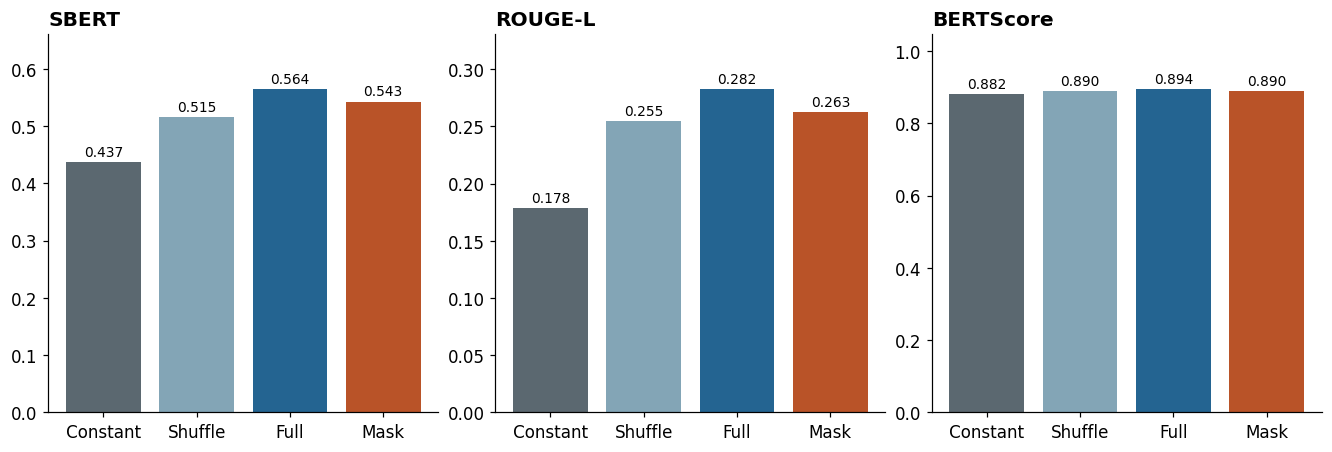

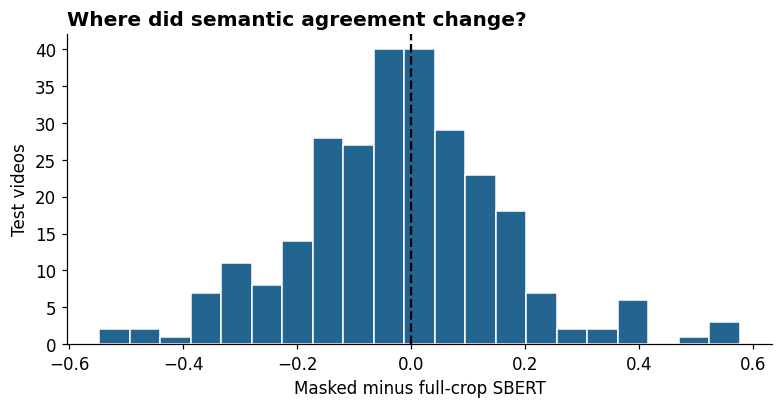

In [7]:
def analyse(rows):
    overall=rows.groupby("system")[metrics].mean().reset_index()
    table(overall,"overall_metrics")
    for field in ["manipulation","seen"]:
        agg=rows.groupby([field,"system"])[metrics].mean()
        agg["videos"]=rows.groupby([field,"system"]).size()
        table(agg.reset_index(),field+"_metrics")
    diversity=rows.groupby("system").caption.agg(videos="size",distinct="nunique",
                 empty=lambda s:s.str.strip().eq("").sum(),top4_share=lambda s:s.value_counts().head(4).sum()/len(s))
    table(diversity.reset_index(),"caption_diversity")
    diffs=[]
    for metric in metrics:
        wide=rows.pivot(index="key",columns="system",values=metric)
        groups=wide.index.str.extract(r"/(\d+)_",expand=False)
        assert not groups.isna().any()
        for left,right in [("Full crop","Shuffled full crop"),("Full crop","Constant"),("Click mask","Full crop"),("Click mask","Constant")]:
            change=wide[left]-wide[right]
            by=change.groupby(groups).agg(["sum","size"])
            draws=np.random.default_rng(42).integers(len(by),size=(2000,len(by)))
            means=by["sum"].to_numpy()[draws].sum(1)/by["size"].to_numpy()[draws].sum(1)
            lo,hi=np.quantile(means,[.025,.975])
            diffs.append((metric,left,right,change.mean(),lo,hi))
    table(pd.DataFrame(diffs,columns=["metric","system","comparator","difference","lower95","upper95"]),"paired_differences")
    fig,axs=plt.subplots(1,3,figsize=(12,4),layout="constrained")
    for ax,metric in zip(axs,metrics):
        ss=overall.set_index("system").loc[labels,metric]
        bars=ax.bar(range(4),ss,color=[grey,"#83a5b6",blue,orange])
        ax.bar_label(bars,fmt="%.3f",fontsize=9,padding=2)
        ax.set(title=metric,xticks=range(4),xticklabels=["Constant","Shuffle","Full","Mask"])
        ax.margins(y=.17)
    save(fig,"06_all_metrics","Original split, matched keys, 271 videos. Shuffle is an input derangement of the full-crop model.")
    wide=rows.pivot(index="key",columns="system",values="SBERT")
    fig,ax=plt.subplots(figsize=(7,3.6),layout="constrained")
    ax.hist(wide["Click mask"]-wide["Full crop"],bins=21,color=blue,edgecolor="white")
    ax.axvline(0,color="black",ls="--")
    ax.set(xlabel="Masked minus full-crop SBERT",ylabel="Test videos",title="Where did semantic agreement change?")
    save(fig,"07_paired_distribution","Each observation is one matched video. Training and decoding differ between systems.")
if paired: analyse(rows)

## 6. Held-out image panels for the presentation
Select one video per manipulation nearest to its median masked-minus-full SBERT difference (ties broken by key). Selection uses captions and scores, not an assumption about visual correctness. Verify each description against all five frames. Training previews above illustrate a different cohort.

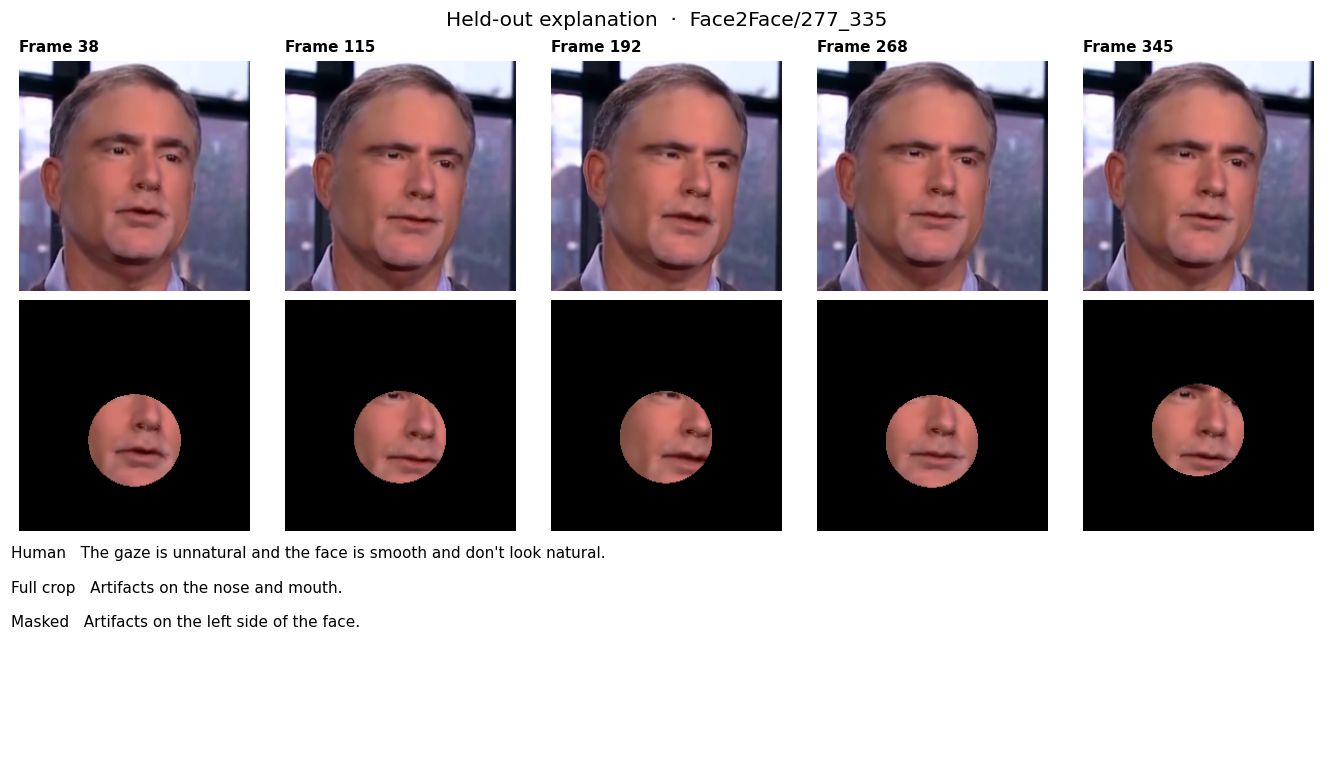

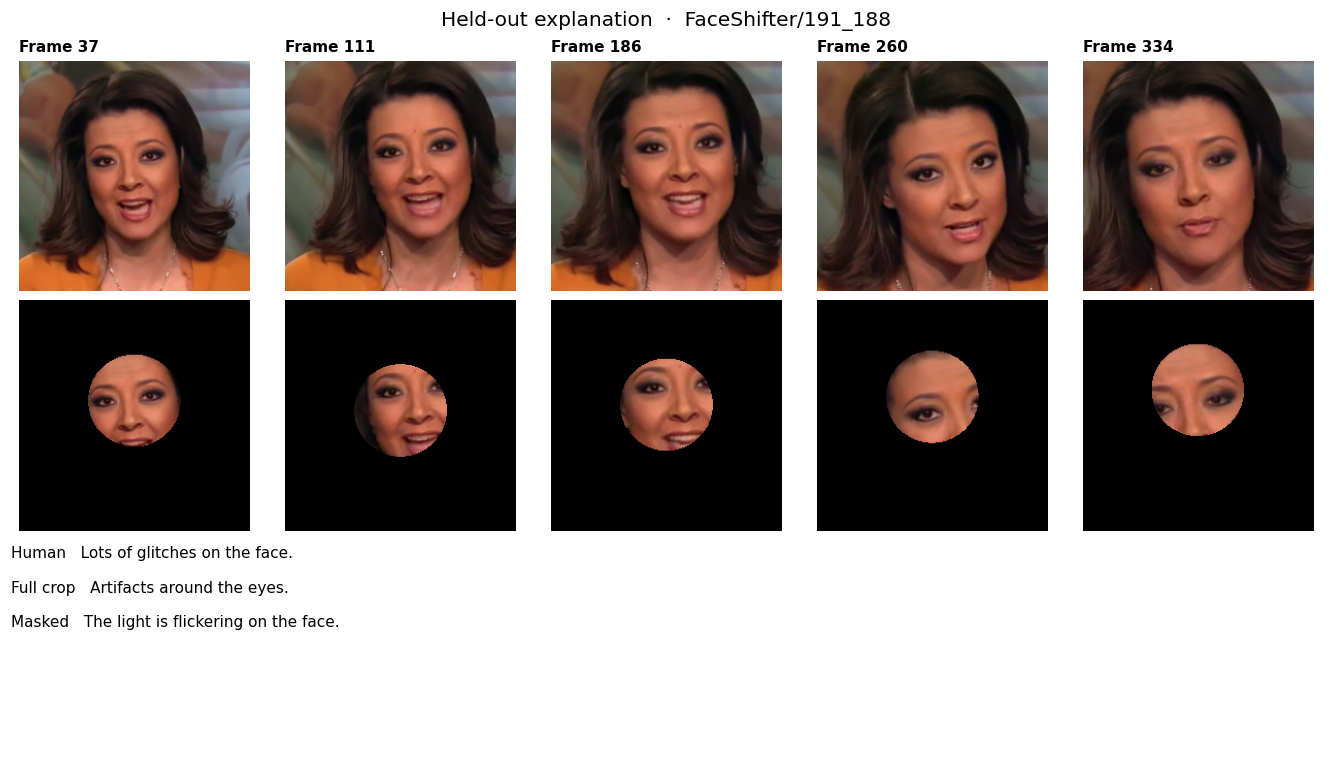

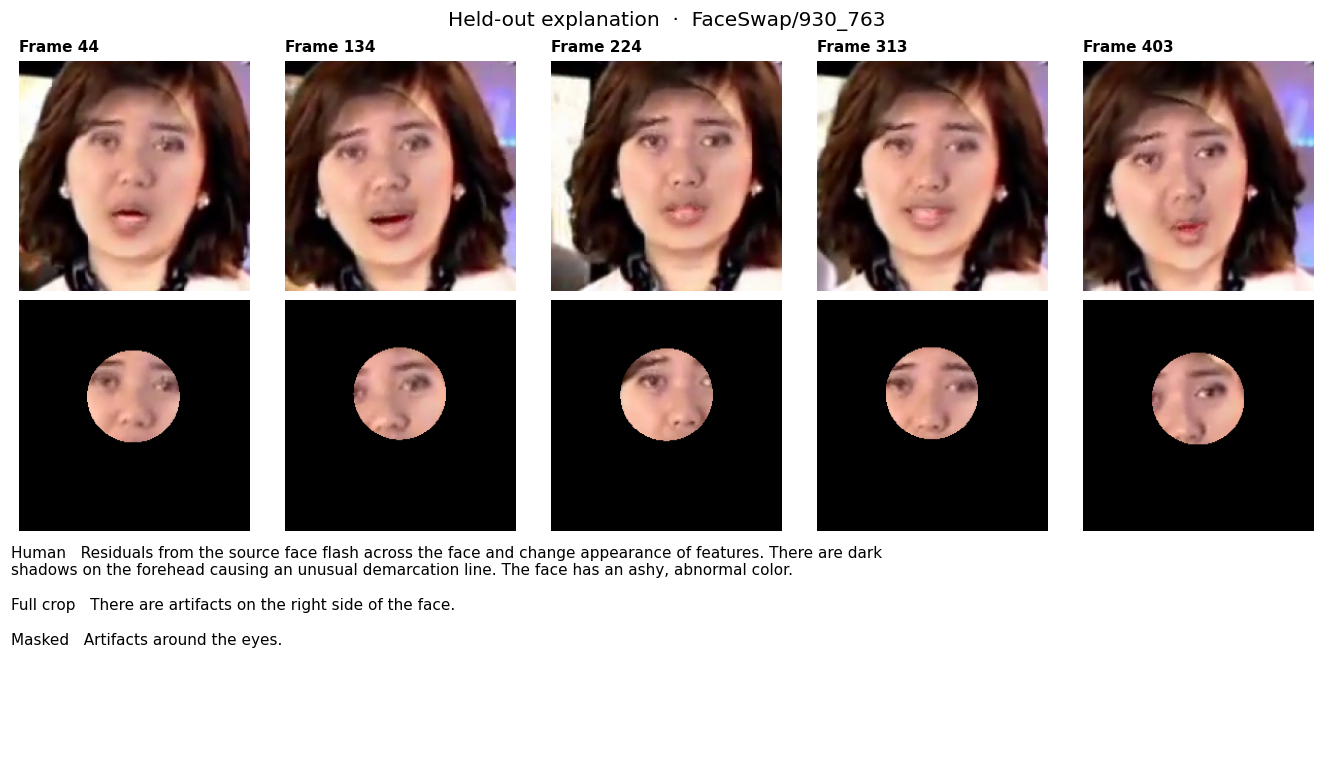

In [8]:
def examples(d,rows,meta,click):
    prep=pd.read_csv(meta,keep_default_na=False)
    points=pd.read_csv(click,keep_default_na=False)
    p=d.merge(prep[["key","crop_paths","frame_idx","split","text"]],on="key",validate="one_to_one",suffixes=("","_prep"))
    p=p.merge(points[["key","pred_clicks","split"]].rename(columns={"split":"split_click"}),on="key",validate="one_to_one")
    assert len(p)==271 and p.split_prep.eq("test").all() and p.split_click.eq("test").all()
    assert p.text.str.strip().eq(p.reference.str.strip()).all()
    scores=rows.pivot(index="key",columns="system",values="SBERT")
    p["delta"]=p.key.map(scores["Click mask"]-scores["Full crop"])
    for method,part in p.sort_values("key").groupby("manipulation"):
        r=part.loc[(part.delta-part.delta.median()).abs().idxmin()]
        paths=json.loads(r.crop_paths); xy=np.array(json.loads(r.pred_clicks)); idx=json.loads(r.frame_idx)
        assert len(paths)==len(idx)==5 and xy.shape==(5,2) and np.isfinite(xy).all() and ((xy>=0)&(xy<=1)).all()
        fig=plt.figure(figsize=(12,7),layout="constrained")
        grid=fig.add_gridspec(3,5,height_ratios=[1,1,1.0])
        for j in range(5):
            with Image.open(meta.parent/paths[j]) as im: rgb=np.array(im.convert("RGB"))
            assert rgb.shape==(224,224,3)
            yy,xx=np.ogrid[:224,:224]; x,y=xy[j]*223
            mask=(xx-x)**2+(yy-y)**2<=(.2*224)**2
            for i,arr in enumerate([rgb,np.where(mask[...,None],rgb,0)]):
                ax=fig.add_subplot(grid[i,j]);ax.imshow(arr);ax.axis("off")
                if i==0: ax.set_title(f"Frame {idx[j]}",fontsize=10)
        ax=fig.add_subplot(grid[2,:]);ax.axis("off")
        lines=[textwrap.fill(f"{label}   {r[col]}",112) for label,col in [("Human","reference"),("Full crop","Full crop"),("Masked","Click mask")]]
        ax.text(0,.98,"\n\n".join(lines),va="top",fontsize=10)
        fig.suptitle("Held-out explanation  ·  "+r.key)
        save(fig,"08_example_"+method,f"{r.key}: full crops above, predicted-click inputs below. Captions are verbatim.")
if paired:
    mp=find_export("metadata.csv",["crop_paths","frame_idx","key","text"],META_CSV)
    cp=find_export("click_preds.csv",["pred_clicks","key","split"],CLICK_CSV)
    if mp and cp: examples(d,rows,mp,cp)
    else: print("Attach extracted Part 1 and Part 2 outputs for new held-out image panels.")

## 7. Conclusions for this semester and next
The correct-video control gap supports some sensitivity to the video. Only 46 distinct full-crop captions and 37 distinct masked captions occurred on 271 tests. The masked model's four most common outputs cover 171 videos. Text similarity alone cannot verify the named feature. Both runs selected epoch 3 and overfit with longer training.

For the current implementation milestone, report the original split, the shuffled and constant controls, real examples and these limitations. For the HPC phase, split source groups before training either model, generate out-of-fold training clicks, and match optimiser settings, seeds and decoding across full, centre-mask and predicted-mask branches. Evaluate multiple seeds and use blinded human checks of location, defect and temporal support. Avoid any real/fake accuracy claim on this fake-only subset.

In [9]:
guide=["# Figure and table guide","", "Evaluation mode: "+("paired prediction CSVs" if paired else "recorded notebook outputs only"),""]
for name,cap in captions.items(): guide.append(f"- {name}: {cap}")
guide+=["","Part 3: 46 distinct captions. Part 4: 37; top four account for 171/271.",
        "These are fake-only explanations; source overlap affects 256/271 test videos.",
        "Masked semantic metrics require the paired prediction files."]
(OUT/"README.md").write_text("\n".join(guide))
archive=shutil.make_archive(str(OUT)+"_results","zip",OUT)
print(archive)
display(FileLink(archive))

/kaggle/working/part5_7iifirps_results.zip


/kaggle/working/part5_7iifirps_results.zip